In [1]:
import sys
from pathlib import Path
# Find the project from either the repository root or the notebook directory.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'tw/decoding_gpu/guven/guven_plot_funcs.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from within the travelling_waves project.")
sys.path.insert(0, str(PROJECT_ROOT / 'tw/decoding_gpu/guven'))
import importlib
import guven_plot_funcs as twplot
twplot = importlib.reload(twplot)

# Use a writable project-local output directory on this machine.
SAVE_ROOT = (PROJECT_ROOT / 'tw/result/figs/guven')
twplot.SAVE_ROOT = str(SAVE_ROOT)


In [2]:
# Paths: edit these three values to control cache loading and figure saving.
CACHE_DIR = (PROJECT_ROOT / 'tw/result/guven_fft')
ACCURACY_CACHE_DIR = None  # Read accuracy from the original behavior files.
BEHAVIOR_DIR = (PROJECT_ROOT / 'guven_data/Raw_Data')
SAVE_ROOT = (PROJECT_ROOT / 'tw/result/figs/guven')
CORRECT_ONLY = False  # True: retain only trials with acc == 1
ROTATION_ONLY = None  # None: all rotations; or select 0, 30, or 60 degrees
twplot.CACHE_DIR = str(CACHE_DIR)
twplot.SAVE_ROOT = str(SAVE_ROOT)
twplot.CORRECT_ONLY = CORRECT_ONLY
twplot.ROTATION_ONLY = ROTATION_ONLY

N_LINES = 5

CONTRA_SEL = [f"C{i}" for i in range(1, N_LINES + 1)]
IPSI_SEL   = [f"I{i}" for i in range(1, N_LINES + 1)]
# CONTRA_SEL = ["C2","C5"]
# IPSI_SEL   = ["I2","I5"]
MID_SEL    = ["M"]
print(f"contra_idx={CONTRA_SEL}  ipsi_idx={IPSI_SEL}  mid_idx={MID_SEL}")


contra_idx=['C1', 'C2', 'C3', 'C4', 'C5']  ipsi_idx=['I1', 'I2', 'I3', 'I4', 'I5']  mid_idx=['M']


In [3]:
by_subj, subj_ids = twplot.load_results(
    CACHE_DIR, accuracy_cache_dir=ACCURACY_CACHE_DIR, behavior_dir=BEHAVIOR_DIR
)
print(f"Subjects: {subj_ids}")
for subj in subj_ids:
    print(subj, sorted(by_subj[subj].keys()))

# peek inside one session dict to see what fields/shapes are actually loaded
example = by_subj[subj_ids[0]][sorted(by_subj[subj_ids[0]].keys())[0]]
print()
print(f"Example: subj={subj_ids[0]} sess={sorted(by_subj[subj_ids[0]].keys())[0]}")
for k, v in example.items():
    if hasattr(v, "shape"):
        print(f"  {k}: shape={v.shape} dtype={v.dtype}")
    else:
        print(f"  {k}: {v!r}" if not isinstance(v, list) or len(v) < 20 else f"  {k}: list(len={len(v)})")


Subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
1 [1, 2, 3, 4]
2 [1, 2, 3, 4]
3 [1, 2, 3, 4]
4 [1, 2, 3, 4]
5 [1, 2, 3, 4]
6 [1, 2, 3, 4]
7 [1, 2, 3, 4]
8 [1, 2, 3, 4]
9 [1, 2, 3, 4]
10 [1, 2, 3, 4]
11 [1, 2, 3, 4]
12 [1, 2, 3, 4]
13 [1, 2, 3, 4]
14 [1, 2, 3, 4]
15 [1, 2, 3, 4]
16 [1, 2, 3, 4]
17 [1, 2, 3, 4]
18 [1, 2, 3, 4]
19 [1, 2, 3, 4]
20 [1, 2, 3, 4]
21 [1, 2, 3, 4]
22 [1, 2, 3, 4]
23 [1, 2, 3, 4]
24 [1, 2, 3, 4]
25 [1, 2, 3, 4]
26 [1, 2, 3, 4]
27 [1, 2, 3, 4]
28 [1, 2, 3, 4]
29 [1, 2, 3, 4]
30 [1, 2, 3, 4]

Example: subj=1 sess=1
  fwMax: shape=(11, 20, 125, 360) dtype=float64
  bwMax: shape=(11, 20, 125, 360) dtype=float64
  fwMaxSS: shape=(11, 20, 125, 360) dtype=float64
  bwMaxSS: shape=(11, 20, 125, 360) dtype=float64
  starts: shape=(125,) dtype=int64
  ff: shape=(20,) dtype=float64
  sfreq: 500
  epoch_tmin: -1.2
  cue_loc: shape=(360,) dtype=int64
  rt: shape=(360,) dtype=float64
  is_bad_epoch: sha

In [ ]:
twplot.print_trial_summary(by_subj, subj_ids)

## TF Maps (cue-aligned: contra / ipsi / mid)

[FW (CONTRA)] cluster 2: p=0.0002, freq=[2.0, 30.0] Hz, time=[-0.25, 1.70] s
[FW (IPSI)] cluster 2: p=0.0002, freq=[2.0, 30.0] Hz, time=[-0.25, 1.70] s
[FW (MID)] cluster 1: p=0.0002, freq=[2.0, 30.0] Hz, time=[-0.25, 1.70] s
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/guven/no-bl/fw_cue_tf_contra-ipsi-mid_0p5-2p45s.png


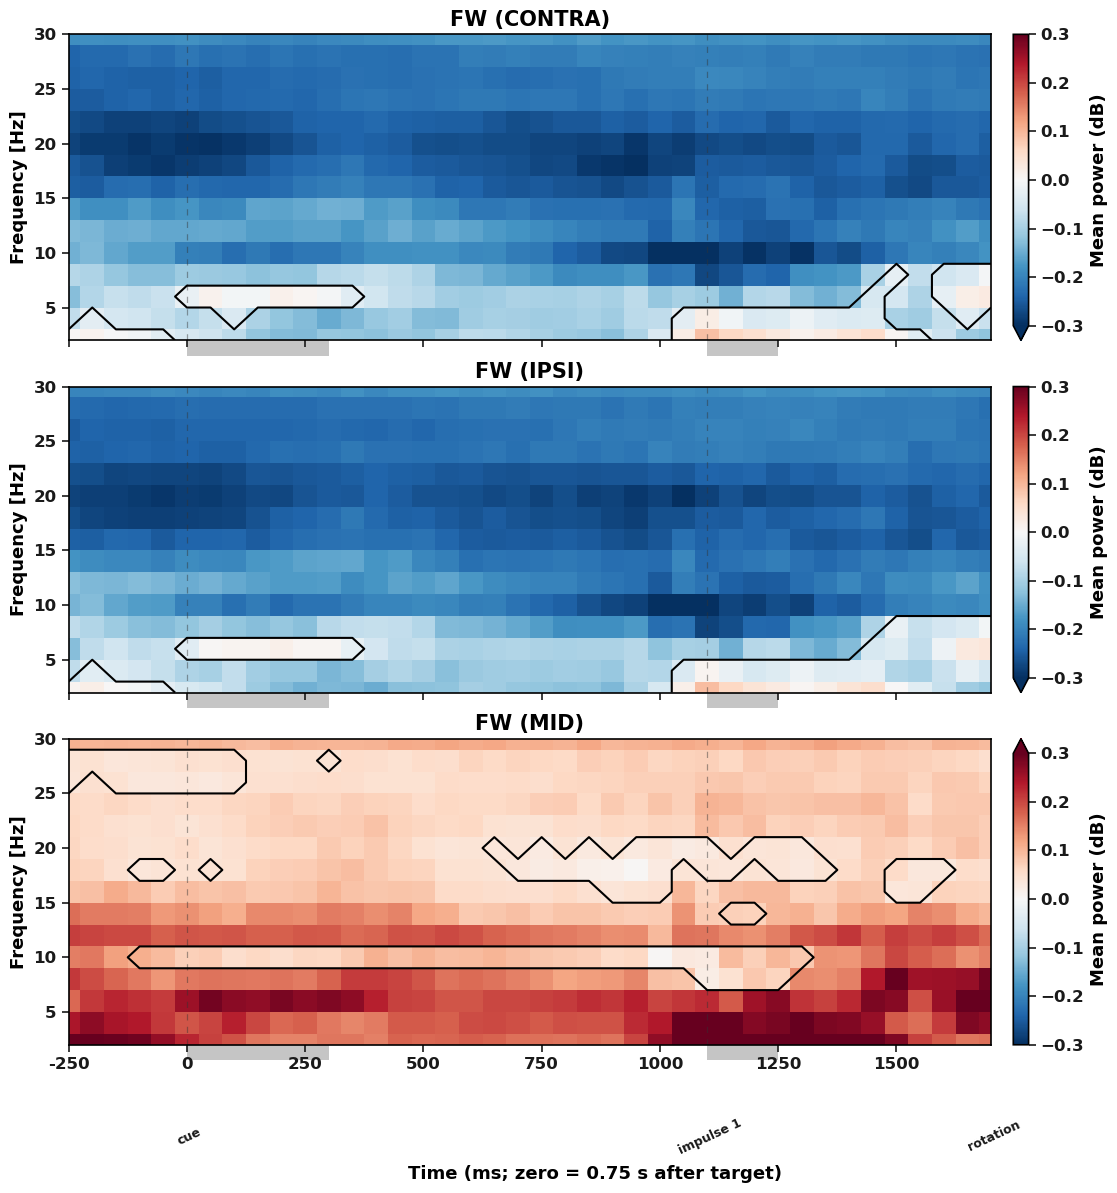

[FW contra - ipsi power -- cue] no significant clusters (p<0.05)
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/guven/no-bl/fw_cue_tf_0p5-2p45s.png


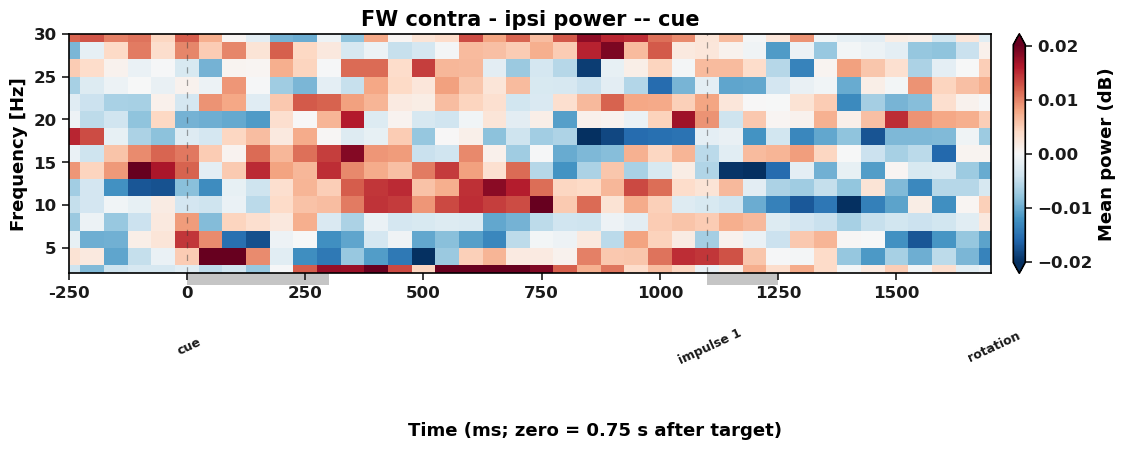

[BW (CONTRA)] cluster 1: p=0.0002, freq=[2.0, 30.0] Hz, time=[-0.25, 1.70] s
[BW (IPSI)] cluster 1: p=0.0002, freq=[2.0, 30.0] Hz, time=[-0.25, 1.70] s
[BW (MID)] cluster 1: p=0.0002, freq=[2.0, 26.0] Hz, time=[-0.25, 1.70] s
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/guven/no-bl/bw_cue_tf_contra-ipsi-mid_0p5-2p45s.png


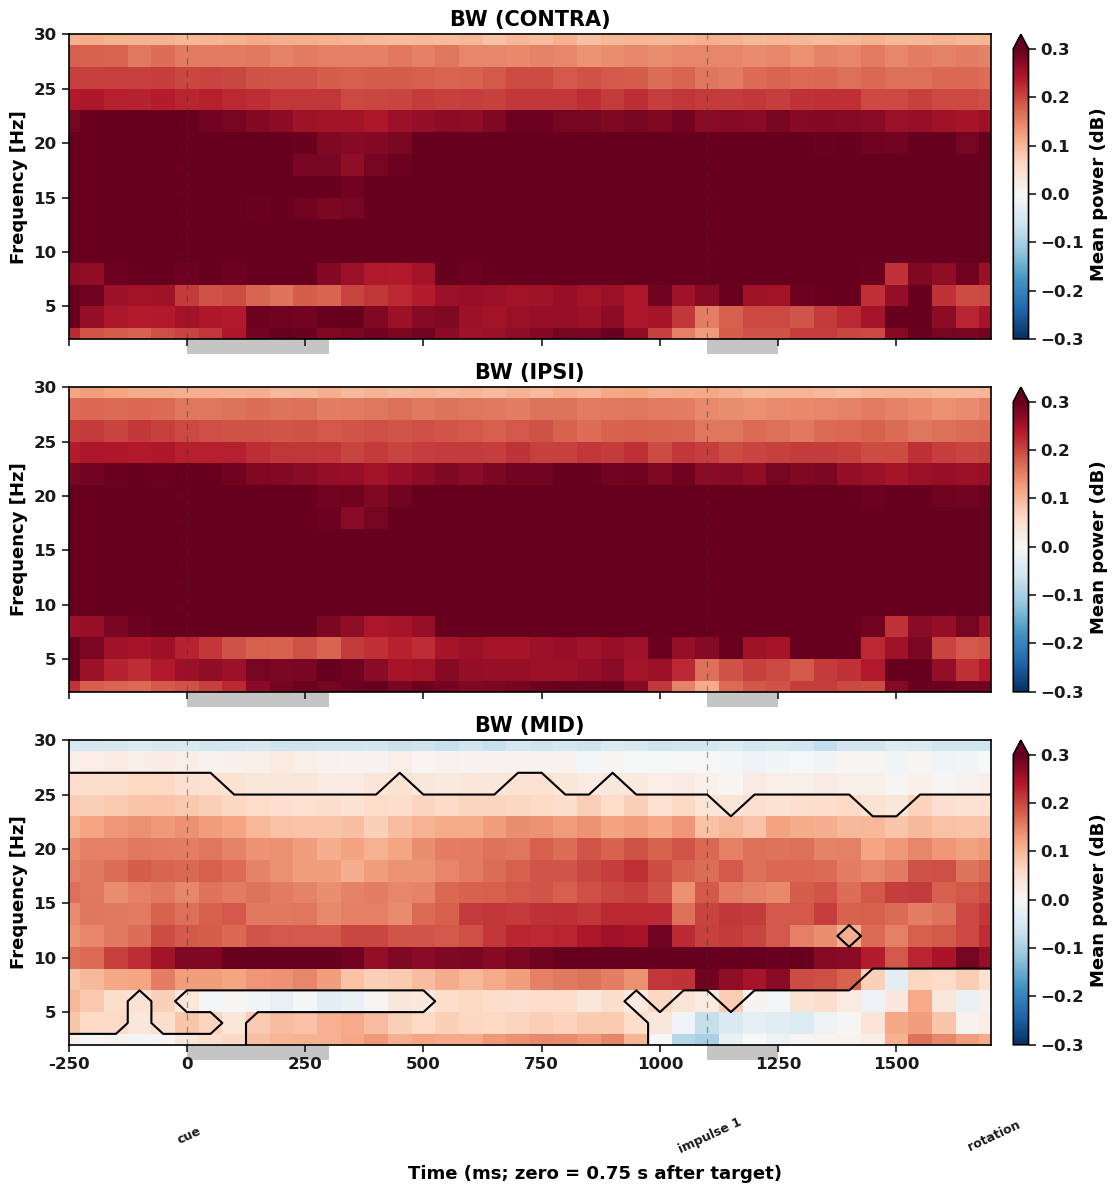

[BW contra - ipsi power -- cue] cluster 25: p=0.0040, freq=[10.0, 12.0] Hz, time=[0.35, 0.75] s
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/guven/no-bl/bw_cue_tf_0p5-2p45s.png


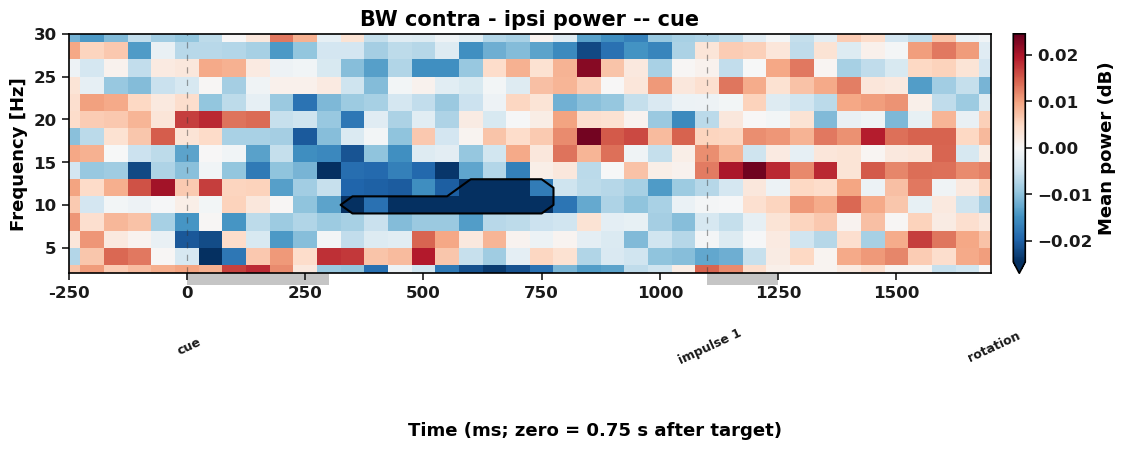

In [4]:
# Restrict both plotting and cluster testing to 0.5–2.45 s (original epoch time).
# Displayed time remains relative to cue onset (0.75 s).
twplot.plot_tf_maps_cue(
    by_subj, subj_ids, baseline_correct=False, measure=["fw", "bw"],
    t_start=0.5, t_stop=2.45,
    contra_idx=CONTRA_SEL, ipsi_idx=IPSI_SEL, mid_idx=MID_SEL,
    exclude_bad=True, fmax=30, diff_vabs=None, diff_percentile=98, time_zero=0.75,
)


## Band Time-Series (CONTRA vs IPSI, per frequency band)

[fw theta(2-6 Hz)] no clusters with p<0.1
[fw alpha (8-12 Hz)] no clusters with p<0.1
[fw beta(14-30 Hz)] no clusters with p<0.1
[fw Beta1 (14-16 Hz)] no clusters with p<0.1
[fw Beta2 (16-18 Hz)] cluster 1: p=0.0896~, time=[0.85, 0.90] s
[fw Beta3 (18-20 Hz)] no clusters with p<0.1


/media/dilay/T7/travelling_waves/tw/decoding_gpu/guven/guven_plot_funcs.py:549: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv
  _, cls, ps, _ = permutation_cluster_1samp_test(


[fw Beta4 (20-22 Hz)] no clusters with p<0.1
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/guven/no-bl/fw_difference_band_0p5-2p45s_zero-0.75s.png


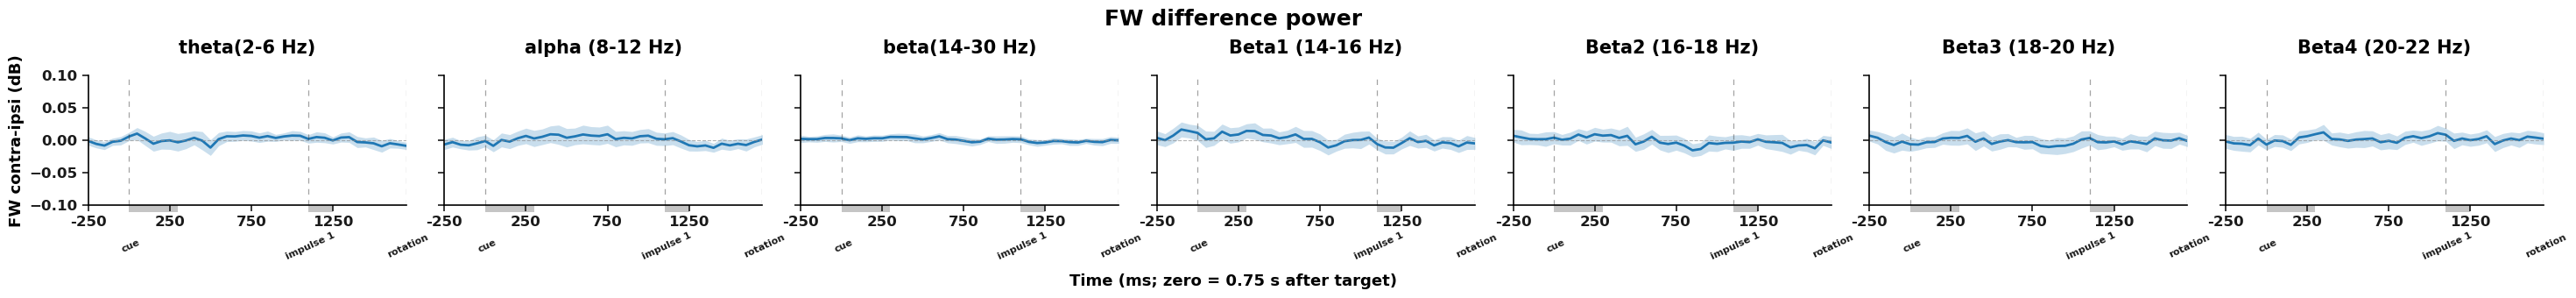

[bw theta(2-6 Hz)] cluster 1: p=0.0650~, time=[-0.20, -0.10] s
[bw alpha (8-12 Hz)] cluster 3: p=0.0030*, time=[0.35, 0.75] s
[bw beta(14-30 Hz)] cluster 4: p=0.0138*, time=[0.25, 0.45] s
[bw Beta1 (14-16 Hz)] cluster 8: p=0.0016*, time=[0.25, 0.55] s
[bw Beta2 (16-18 Hz)] cluster 1: p=0.0354*, time=[0.80, 0.90] s
[bw Beta2 (16-18 Hz)] cluster 4: p=0.0312*, time=[0.25, 0.35] s
[bw Beta3 (18-20 Hz)] no clusters with p<0.1
[bw Beta4 (20-22 Hz)] cluster 2: p=0.0906~, time=[0.25, 0.35] s
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/guven/no-bl/bw_difference_band_0p5-2p45s_zero-0.75s.png


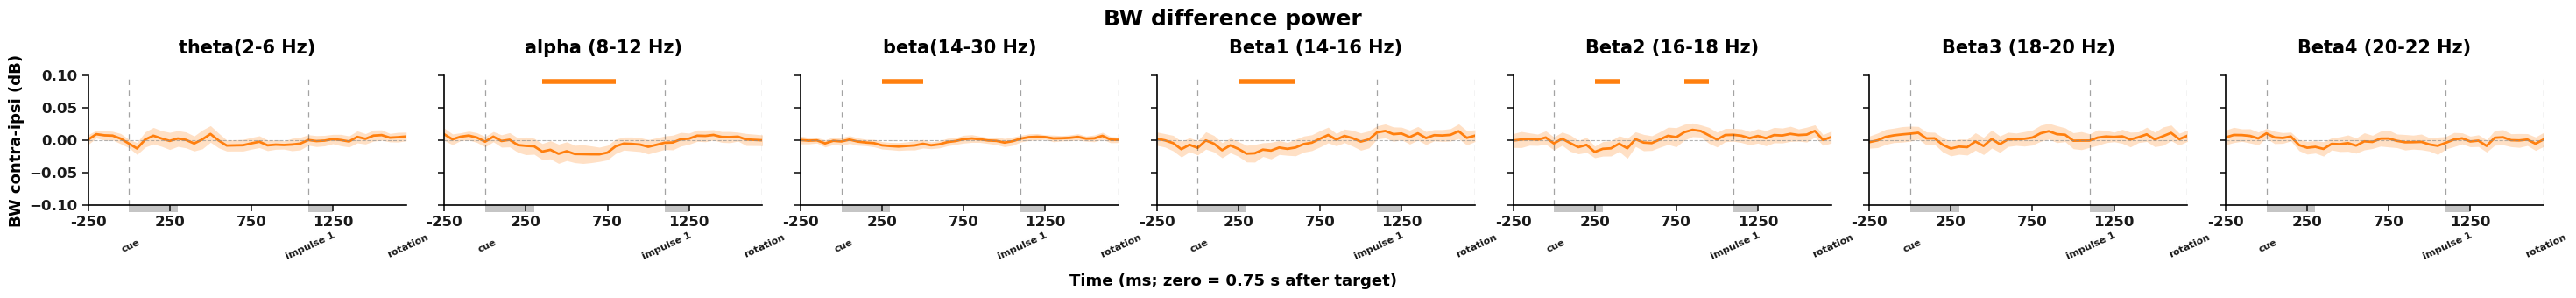

In [5]:
#cue period
twplot.plot_band_timeseries_cue(by_subj, subj_ids, baseline_correct=False, measure=["fw", "bw"], split_measures=True, exclude_bad=True,
                             t_start= 0.5, t_stop = 2.45,  
                              contra_idx=CONTRA_SEL, ipsi_idx=IPSI_SEL, ylim=(-0.1, 0.1),
                              time_zero= 0.75, hide_right_event_label=False)

In [ ]:
twplot.plot_band_timeseries_cue(by_subj, subj_ids, baseline_correct=False, measure=["fw", "bw"], split_measures=True, exclude_bad=True,
                             t_start= 1.6, t_stop = 3.05,  #t_start=0.55, t_stop=2.45,
                              contra_idx=CONTRA_SEL, ipsi_idx=IPSI_SEL, ylim=(-0.1, 0.1),
                              time_zero=1.85, hide_right_event_label=True)

### Pairwise Cn–In lateralization

In [ ]:
# One combined FW/BW figure for each matched contra–ipsi pair (five figures total).
pairwise_save_root = SAVE_ROOT / 'pairwise_lateralization'

for pair_number in range(1, N_LINES + 1):
    contra_name = f'C{pair_number}'
    ipsi_name = f'I{pair_number}'
    pair_name = f'{contra_name}-{ipsi_name}'
    print(f'\n=== {pair_name}: contra - ipsi ===')

    twplot.plot_band_timeseries_cue(
        by_subj, subj_ids,
        baseline_correct=False,
        measure=['fw', 'bw'],
        split_measures=False,
        exclude_bad=True,
        t_start=0, t_stop=1.85,
        contra_idx=[contra_name],
        ipsi_idx=[ipsi_name],
        ylim=(-0.1, 0.1),
        time_zero=0,
        hide_right_event_label=True,
        title=f'{pair_name}: FW/BW contra-ipsi band power — Cue-aligned',
        save_root=pairwise_save_root / pair_name,
    )

## All Lines Average (grand-average traveling wave, no contra/ipsi split)

In [ ]:
twplot.plot_all_lines_measures_cue(by_subj, subj_ids, t_start=0.5, t_stop=2.45, time_zero=0.75, baseline_correct=False, measure=["fw", "bw", "ratio"], exclude_bad=True, line_idx=CONTRA_SEL + IPSI_SEL + MID_SEL, ylim=(-0.5, 0.5))

In [ ]:
# Compare 0°, 30°, and 60° rotation: cue-aligned CONTRA - IPSI.
# This cell compares all rotations and therefore ignores the global ROTATION_ONLY,
# while still respecting CORRECT_ONLY and exclude_bad=True.
rotation_diff_curves, rotation_diff_counts, rotation_diff_stats = (
    twplot.plot_rotation_comparison(
        by_subj, subj_ids, mode='difference', rotations=(0, 30, 60),
        measures=('fw', 'bw'), exclude_bad=True,
        contra_idx=CONTRA_SEL, ipsi_idx=IPSI_SEL,
        t_start=0.5, t_stop=2.45, time_zero=0.75,
        n_permutations=5000, save_root=SAVE_ROOT, combine_measures=True,
    )
)

In [ ]:
# Compare 0°, 30°, and 60° rotation: average across all 11 lines.
rotation_all_curves, rotation_all_counts, rotation_all_stats = (
    twplot.plot_rotation_comparison(
        by_subj, subj_ids, mode='all_lines', t_start=0.5, t_stop=4.15, time_zero=0.75, rotations=(0, 30, 60),
        baseline_correct=False, bl0=-0.45,bl1=-0.25,
        measures=('fw', 'bw'), exclude_bad=True,
        line_idx=CONTRA_SEL + IPSI_SEL + MID_SEL,
        n_permutations=5000, save_root=SAVE_ROOT,
    )
)